# Point-mass trajectory optimization with a vector field

A planar mass starts at rest and has three seconds to reach $(3,2)$ m at rest. Its state is $[p_x,p_y,v_x,v_y]$ and its control is acceleration. A factor graph specifies the position, velocity, and effort penalties. The vector field supplies the time derivative for each rollout. [C++ example](https://github.com/borglab/gtsam/blob/develop/gtsam_unstable/examples/mppi/PointMassMPPITrajectoryOptimizationExample.cpp)

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/python/gtsam_unstable/examples/planning/PointMassMPPITrajectoryOptimizationExample.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
import gtsam_unstable as unstable
from gtsam.symbol_shorthand import U, X
from plotly.subplots import make_subplots
from IPython.display import HTML, display

teal, orange = "#087B78", "#B65025"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Build the cost graph

The order of the state and control keys defines the 30-step horizon. The intermediate priors favor early progress, the terminal prior emphasizes arrival at rest, and the control priors penalize acceleration. Their precisions multiply the squared residuals in the graph error.

In [3]:
H, dt = 30, 0.1
state_keys = [X(k) for k in range(H + 1)]
control_keys = [U(k) for k in range(H)]
start, goal = np.zeros(4), np.array([3., 2., 0., 0.])
running = gtsam.noiseModel.Diagonal.Precisions(np.array([1., 1., 0.1, 0.1]))
terminal = gtsam.noiseModel.Diagonal.Precisions(np.array([100., 100., 10., 10.]))
effort = gtsam.noiseModel.Isotropic.Precision(2, 0.1)

graph = gtsam.NonlinearFactorGraph()
for k, key in enumerate(control_keys):
    graph.add(gtsam.PriorFactorVector(key, np.zeros(2), effort))
    graph.add(gtsam.PriorFactorVector(state_keys[k + 1], goal, terminal if k == H - 1 else running))

## Predict, sample, and update

`PointMass.dynamics` returns the tangent velocity $[v_x,v_y,a_x,a_y]$. `SamplingPlanner` advances the Euclidean state by $x_{k+1}=x_k+\Delta t\,f(x_k,u_k)$. The native `pointMassVectorField()` adapter makes this derivative available to the planner. The initial rollout fills the horizon from the measured state and a $2\times30$ zero-control matrix. Each MPPI iteration scores 1,024 candidate sequences drawn from the Gaussian proposal, with standard deviation 0.5 m/s² in each acceleration coordinate. The same three objects carry out all 30 updates.

In [4]:
planner = gtsam.SamplingPlannerVectorVector(state_keys, control_keys, dt)
proposal = gtsam.GaussianProposal(0.25 * np.eye(2), 1024, 42)
rule = gtsam.MPPI(1.0)
seed = gtsam.Values()
seed.insert(X(0), start)
zero_controls = np.zeros((2, H))
dynamics = unstable.pointMassVectorField()
initial = planner.rollout(seed, zero_controls, dynamics)
plan = planner.optimize(graph, initial, dynamics, proposal, rule, 30)

## Read the trajectory

Each column of the nominal control matrix governs one time interval. The returned plan contains 30 controls and 31 states. Graph error measures the complete objective, while terminal distance and speed quantify arrival accuracy.

In [5]:
states = np.array([plan.atVector(key) for key in state_keys])
controls = planner.nominalControls(plan).T
time = dt * np.arange(H + 1)
speed = np.linalg.norm(states[:, 2:], axis=1)
distance = np.linalg.norm(states[-1, :2] - goal[:2])
print(f"Graph error {graph.error(initial):.2f} → {graph.error(plan):.2f}")
print(f"Terminal distance {distance:.3f} m, speed {speed[-1]:.3f} m/s")

Graph error 838.50 → 57.96
Terminal distance 0.022 m, speed 0.073 m/s


Position markers are spaced half a second apart. Their spacing shows when the mass accelerates and slows. The speed profile and the two held acceleration commands give the same motion in time. Hover over a marker for its time and speed. Interactive figures require an internet connection.

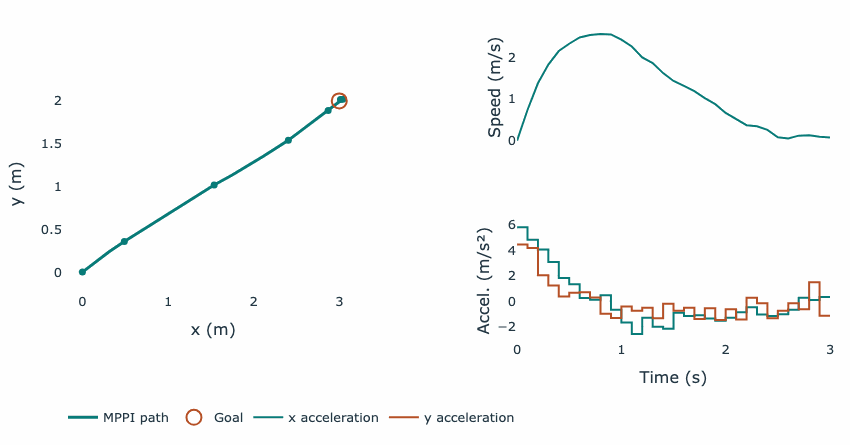

In [6]:
fig = make_subplots(rows=2, cols=2, specs=[[{"rowspan": 2}, {}], [None, {}]],
                    column_widths=[0.49, 0.51], horizontal_spacing=0.20, vertical_spacing=0.24)
fig.add_scatter(x=states[:, 0], y=states[:, 1], mode="lines", line=dict(color=teal, width=3),
                name="MPPI path", row=1, col=1)
fig.add_scatter(x=states[::5, 0], y=states[::5, 1], mode="markers", showlegend=False,
                marker=dict(color=teal, size=7), customdata=np.c_[time[::5], speed[::5]],
                hovertemplate="%{customdata[0]:.1f} s · %{customdata[1]:.2f} m/s<extra></extra>",
                row=1, col=1)
fig.add_scatter(x=[goal[0]], y=[goal[1]], mode="markers", name="Goal",
                marker=dict(symbol="circle-open", size=15, color=orange, line_width=2), row=1, col=1)
fig.add_scatter(x=time, y=speed, mode="lines", line=dict(color=teal),
                name="Speed", showlegend=False, row=1, col=2)
for axis, label, color in [(0, "x acceleration", teal), (1, "y acceleration", orange)]:
    fig.add_scatter(x=time, y=np.r_[controls[:, axis], controls[-1, axis]], mode="lines",
                    line=dict(shape="hv", color=color), name=label, row=2, col=2)
fig.update_xaxes(title_text="x (m)", row=1, col=1)
fig.update_yaxes(title_text="y (m)", scaleanchor="x", scaleratio=1, constrain="domain", row=1, col=1)
fig.update_yaxes(title_text="Speed (m/s)", title_standoff=3, row=1, col=2)
fig.update_yaxes(title_text="Accel. (m/s²)", title_standoff=3, row=2, col=2)
fig.update_xaxes(matches="x3", showticklabels=False, row=1, col=2)
fig.update_xaxes(title_text="Time (s)", row=2, col=2)
fig.update_layout(template="plotly_white", height=445, margin=dict(l=63, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.20, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Point-mass trajectory optimization with a vector field" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))